# Práctica 4: Clasificación de MNIST mediante Transfer Learning


In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.applications import VGG16, ResNet50, MobileNetV2
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

# Configuración estética de gráficos
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context("notebook", font_scale=1.1)
print("Versión de TensorFlow:", tf.__version__)

Versión de TensorFlow: 2.21.0


## 1. Carga y Preprocesamiento de Datos

Los modelos pre-entrenados en *ImageNet* tienen dos restricciones arquitectónicas respecto a las imágenes originales de MNIST:
1. **Canales de color:** Esperan imágenes RGB de **3 canales**, mientras que MNIST está en escala de grises (**1 canal**).
2. **Resolución espacial:** El tamaño original de MNIST es de `28x28` píxeles. Sin embargo, arquitecturas profundas como `VGG16` o `ResNet50` reducen espacialmente los mapas de características mediante múltiples bloques de *Pooling* (dividiendo por un factor de $2^5 = 32$), por lo que exigen un tamaño mínimo de entrada de **`32x32` píxeles** (siendo `224x224` el estándar original de ImageNet).

**Optimización de Memoria en Google Colab:** Redimensionar 60.000 imágenes a `224x224x3` directamente en un array de NumPy consumiría más de 36 GB de RAM, provocando la caída del entorno. Para evitarlo, mantendremos los datos en `28x28x1` en memoria e integraremos la conversión a 3 canales, el redimensionado espacial (`32x32`) y la normalización específica de cada fabricante **dentro de las primeras capas del modelo**.

In [2]:
# 1. Carga de datos MNIST
(x_train_full, y_train_full), (x_test, y_test) = mnist.load_data()

# Mantenemos los valores en [0, 255] en float32 para que las funciones
# preprocess_input nativas de VGG16 y ResNet50 trabajen en su escala original
x_train_full = np.expand_dims(x_train_full.astype('float32'), axis=-1)
x_test = np.expand_dims(x_test.astype('float32'), axis=-1)

# Separamos un 10% para validación de forma estratificada y reproducible
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.1, random_state=42, stratify=y_train_full
)

print(f"Entrenamiento: {x_train.shape} | Validación: {x_val.shape} | Test: {x_test.shape}")

# Creamos pipelines tf.data.Dataset para acelerar la carga en GPU
BATCH_SIZE = 128
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train)).shuffle(10000, seed=42).batch(BATCH_SIZE).prefetch(AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test)).batch(BATCH_SIZE).prefetch(AUTOTUNE)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Entrenamiento: (54000, 28, 28, 1) | Validación: (6000, 28, 28, 1) | Test: (10000, 28, 28, 1)


## 2. Diseño de las Propuestas de Transfer Learning

Siguiendo el cuaderno de referencia, vamos a diseñar y comparar **4 propuestas basadas en modelos pre-entrenados**:

1. **Propuesta 1: `VGG16` (Feature Extraction)**
   - Base convolucional pre-entrenada en ImageNet con pesos congelados (`base.trainable = False`).
   - Cabecera clasificadora propia con `GlobalAveragePooling2D`, capa densa de 128 neuronas con `Dropout(0.3)` y salida `Softmax`.
2. **Propuesta 2: `ResNet50` (Feature Extraction)**
   - Base residual de 50 capas congelada (`base.trainable = False`) con la misma cabecera clasificadora.
3. **Propuesta 3: `MobileNetV2` (Feature Extraction)**
   - Arquitectura ligera basada en convoluciones separables en profundidad con pesos congelados (`base.trainable = False`).
4. **Propuesta 4: `VGG16` + Fine-Tuning (Ajuste Fino en 2 Fases)**
   - Descongelamos el último bloque convolucional (`block5`) del modelo VGG16 ya estabilizado y re-entrenamos con una tasa de aprendizaje muy baja ($1e^{-5}$) para adaptar los filtros profundos a la morfología de los dígitos de MNIST.

In [3]:
IMG_SIZE = 32  # Tamaño espacial adaptado (32x32x3)

def crear_modelo_transfer(nombre_base, lr=1e-3, seed=42):
    """
    Construye un modelo de Transfer Learning adaptando la entrada (28, 28, 1)
    a (32, 32, 3) y aplicando el preprocesamiento específico de cada arquitectura.
    """
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    inputs = tf.keras.Input(shape=(28, 28, 1), name="input_mnist")

    # 1. Conversión de 1 canal (Escala de grises) a 3 canales (RGB) concatenando el tensor
    x = tf.keras.layers.Concatenate(axis=-1, name="gris_a_rgb")([inputs, inputs, inputs])

    # 2. Redimensionado espacial a (32, 32)
    x = tf.keras.layers.Resizing(IMG_SIZE, IMG_SIZE, interpolation="bilinear", name="resize_32x32")(x)

    # 3. Selección del preprocesamiento y carga del modelo base (include_top=False)
    if nombre_base == "VGG16":
        x = tf.keras.layers.Lambda(vgg_preprocess, name="preprocess_vgg16")(x)
        base_model = VGG16(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    elif nombre_base == "ResNet50":
        x = tf.keras.layers.Lambda(resnet_preprocess, name="preprocess_resnet50")(x)
        base_model = ResNet50(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    elif nombre_base == "MobileNetV2":
        x = tf.keras.layers.Lambda(mobilenet_preprocess, name="preprocess_mobilenet")(x)
        base_model = MobileNetV2(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    else:
        raise ValueError("Modelo base no reconocido.")

    # Congelamos los pesos del modelo base (Feature Extraction)
    base_model.trainable = False

    # Pasamos las características por la base en modo inferencia (training=False)
    # Esto es crucial para que las capas BatchNormalization de ResNet50/MobileNetV2 no alteren sus estadísticas
    x = base_model(x, training=False)

    # 4. Cabecera de clasificación personalizada (Top Model)
    x = tf.keras.layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    x = tf.keras.layers.Dense(128, activation="relu", name="dense_128")(x)
    x = tf.keras.layers.Dropout(0.3, name="dropout_03")(x)
    outputs = tf.keras.layers.Dense(10, activation="softmax", name="output_digits")(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name=f"TL_{nombre_base}")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model, base_model

## 3. Estudio Experimental y Entrenamiento de Modelos

A continuación, entrenamos nuestras propuestas registrando sus curvas de aprendizaje, tiempos de cómputo, exactitud (*accuracy*), número total de fallos y matrices de confusión.

In [4]:
propuestas_base = [
    {"nombre": "TL - VGG16 (Congelado)", "base": "VGG16", "epochs": 6, "lr": 1e-3},
    {"nombre": "TL - ResNet50 (Congelado)", "base": "ResNet50", "epochs": 6, "lr": 1e-3},
    {"nombre": "TL - MobileNetV2 (Congelado)", "base": "MobileNetV2", "epochs": 6, "lr": 1e-3}
]

resultados = []
historiales = {}
matrices_confusion = {}
modelos_entrenados = {}

mejor_modelo_tl = None
mejor_acc_val = 0.0
nombre_mejor_tl = ""

# --- FASE 1: Entrenamiento mediante Extracción de Características (Pesos Congelados) ---
for prop in propuestas_base:
    nombre = prop["nombre"]
    print(f"\n{'='*65}\nEntrenando: {nombre}\n{'='*65}")

    modelo, base_layer = crear_modelo_transfer(prop["base"], lr=prop["lr"])

    inicio = time.time()
    hist = modelo.fit(train_ds, validation_data=val_ds, epochs=prop["epochs"], verbose=1)
    tiempo = time.time() - inicio

    historiales[nombre] = hist.history
    modelos_entrenados[prop["base"]] = (modelo, base_layer)

    # Evaluación
    acc_train = modelo.evaluate(train_ds, verbose=0)[1]
    acc_val = modelo.evaluate(val_ds, verbose=0)[1]
    acc_test = modelo.evaluate(test_ds, verbose=0)[1]

    y_pred_test = modelo.predict(test_ds, verbose=0).argmax(axis=1)
    errores_test = int(np.sum(y_test != y_pred_test))
    matrices_confusion[nombre] = confusion_matrix(y_test, y_pred_test)

    resultados.append({
        "Modelo / Configuración": nombre,
        "Tipo": "Transfer Learning (Feature Extraction)",
        "Tiempo (s)": round(tiempo, 2),
        "Acc Train": round(acc_train, 4),
        "Acc Val": round(acc_val, 4),
        "Acc Test": round(acc_test, 4),
        "Errores Test (de 10k)": errores_test
    })

    if acc_val > mejor_acc_val:
        mejor_acc_val = acc_val
        mejor_modelo_tl = modelo
        nombre_mejor_tl = nombre


Entrenando: TL - VGG16 (Congelado)
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Epoch 1/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 27ms/step - accuracy: 0.7779 - loss: 1.1927 - val_accuracy: 0.8988 - val_loss: 0.3232
Epoch 2/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8899 - loss: 0.3400 - val_accuracy: 0.9217 - val_loss: 0.2396
Epoch 3/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9118 - loss: 0.2756 - val_accuracy: 0.9325 - val_loss: 0.2159
Epoch 4/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9208 - loss: 0.2447 - val_accuracy: 0.9305 - val_loss: 0.2137
Epoch 5/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9288 - loss: 0.2218 - val_accuracy: 0.9375 - val_loss: 0.1967
Epoch 6/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9312 - loss: 0.2084 - val_accuracy: 0.9402 - val_loss: 0.1887

Entrenando: TL - ResNet50 (Congelado)
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Epoch 1/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 28s 40ms/step -

/tmp/ipykernel_1409/1548939317.py:28: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 24s 31ms/step - accuracy: 0.5310 - loss: 1.4451 - val_accuracy: 0.6122 - val_loss: 1.1621
Epoch 2/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6084 - loss: 1.1434 - val_accuracy: 0.6347 - val_loss: 1.0774
Epoch 3/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6222 - loss: 1.0855 - val_accuracy: 0.6462 - val_loss: 1.0394
Epoch 4/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6334 - loss: 1.0514 - val_accuracy: 0.6497 - val_loss: 1.0149
Epoch 5/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6421 - loss: 1.0274 - val_accuracy: 0.6563 - val_loss: 0.9938
Epoch 6/6
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6451 - loss: 1.0100 - val_accuracy: 0.6623 - val_loss: 0.9780


In [5]:
# --- FASE 2: Propuesta 4 - Fine-Tuning (Ajuste Fino) sobre VGG16 ---
nombre_ft = "TL - VGG16 (Fine-Tuning)"
print(f"\n{'='*65}\nEntrenando: {nombre_ft}\n{'='*65}")

# Recuperamos el modelo VGG16 que ya tiene la cabecera estabilizada
modelo_vgg_ft, base_vgg = modelos_entrenados["VGG16"]

# Descongelamos únicamente el último bloque convolucional (block5)
base_vgg.trainable = True
for layer in base_vgg.layers:
    if not layer.name.startswith("block5"):
        layer.trainable = False

# Recompilamos con un Learning Rate muy bajo (1e-5) para no destruir los pesos pre-entrenados
modelo_vgg_ft.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

inicio_ft = time.time()
hist_ft = modelo_vgg_ft.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=[early_stop], verbose=1)
tiempo_ft = time.time() - inicio_ft

# Concatenamos el historial de la Fase 1 y Fase 2 para ver la evolución completa
historiales[nombre_ft] = {
    "loss": historiales["TL - VGG16 (Congelado)"]["loss"] + hist_ft.history["loss"],
    "val_loss": historiales["TL - VGG16 (Congelado)"]["val_loss"] + hist_ft.history["val_loss"],
    "accuracy": historiales["TL - VGG16 (Congelado)"]["accuracy"] + hist_ft.history["accuracy"],
    "val_accuracy": historiales["TL - VGG16 (Congelado)"]["val_accuracy"] + hist_ft.history["val_accuracy"]
}

# Evaluación tras el Fine-Tuning
acc_train_ft = modelo_vgg_ft.evaluate(train_ds, verbose=0)[1]
acc_val_ft = modelo_vgg_ft.evaluate(val_ds, verbose=0)[1]
acc_test_ft = modelo_vgg_ft.evaluate(test_ds, verbose=0)[1]

y_pred_ft = modelo_vgg_ft.predict(test_ds, verbose=0).argmax(axis=1)
errores_ft = int(np.sum(y_test != y_pred_ft))
matrices_confusion[nombre_ft] = confusion_matrix(y_test, y_pred_ft)

resultados.append({
    "Modelo / Configuración": nombre_ft,
    "Tipo": "Transfer Learning (Fine-Tuning)",
    "Tiempo (s)": round(tiempo_ft, 2),
    "Acc Train": round(acc_train_ft, 4),
    "Acc Val": round(acc_val_ft, 4),
    "Acc Test": round(acc_test_ft, 4),
    "Errores Test (de 10k)": errores_ft
})

if acc_val_ft > mejor_acc_val:
    mejor_acc_val = acc_val_ft
    mejor_modelo_tl = modelo_vgg_ft
    nombre_mejor_tl = nombre_ft


Entrenando: TL - VGG16 (Fine-Tuning)
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.9596 - loss: 0.1297 - val_accuracy: 0.9732 - val_loss: 0.0953
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9752 - loss: 0.0800 - val_accuracy: 0.9768 - val_loss: 0.0804
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9818 - loss: 0.0605 - val_accuracy: 0.9795 - val_loss: 0.0748
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9854 - loss: 0.0484 - val_accuracy: 0.9840 - val_loss: 0.0647
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9869 - loss: 0.0421 - val_accuracy: 0.9822 - val_loss: 0.0675


## 4. Integración y Comparativa con los Modelos de Prácticas Anteriores

Como disponemos de los modelos entrenados en las prácticas anteriores almacenados en el disco duro de Google Colab (`mejor_modelo_p1.keras` y `mejor_modelo_cnn_mnist.keras`), vamos a verificar su existencia en el entorno para evaluarlos en vivo sobre el conjunto de Test, o bien incorporar sus métricas oficiales obtenidas en las prácticas previas para enriquecer nuestra tabla comparativa.

In [6]:
# Datos normalizados [0, 1] para evaluar los modelos de las prácticas 1 y 3
x_test_norm = x_test / 255.0

# 1. Evaluación / Recuperación del MLP (Práctica 1)
ruta_p1 = "mejor_modelo_p1.keras"
if os.path.exists(ruta_p1):
    print(f"Cargando modelo de la Práctica 1 desde disco: '{ruta_p1}'...")
    modelo_p1 = tf.keras.models.load_model(ruta_p1)
    x_test_flat = x_test_norm.squeeze(-1)
    acc_test_p1 = modelo_p1.evaluate(x_test_flat, y_test, verbose=0)[1]
    y_pred_p1 = modelo_p1.predict(x_test_flat, verbose=0).argmax(axis=1)
    err_p1 = int(np.sum(y_test != y_pred_p1))
    matrices_confusion["Práctica 1: MLP Denso (15 Épocas)"] = confusion_matrix(y_test, y_pred_p1)
    resultados.append({
        "Modelo / Configuración": "Práctica 1: MLP Denso (15 Épocas)",
        "Tipo": "Entrenado desde cero (Disco)",
        "Tiempo (s)": 75.48,
        "Acc Train": 0.9980,
        "Acc Val": 0.9798,
        "Acc Test": round(acc_test_p1, 4),
        "Errores Test (de 10k)": err_p1
    })
else:
    print(f"Archivo '{ruta_p1}' no encontrado en el directorio actual. Se añaden los registros de la Práctica 1.")
    resultados.append({
        "Modelo / Configuración": "Práctica 1: MLP Denso (15 Épocas)",
        "Tipo": "Referencia Práctica 1 (MLP)",
        "Tiempo (s)": 75.48,
        "Acc Train": 0.9980,
        "Acc Val": 0.9798,
        "Acc Test": 0.9772,
        "Errores Test (de 10k)": 228
    })

# 2. Evaluación / Recuperación de la CNN Intermedia (Práctica 3)
ruta_p3 = "mejor_modelo_cnn_mnist.keras"
if os.path.exists(ruta_p3):
    print(f"Cargando modelo de la Práctica 3 desde disco: '{ruta_p3}'...")
    modelo_p3 = tf.keras.models.load_model(ruta_p3)
    acc_test_p3 = modelo_p3.evaluate(x_test_norm, y_test, verbose=0)[1]
    y_pred_p3 = modelo_p3.predict(x_test_norm, verbose=0).argmax(axis=1)
    err_p3 = int(np.sum(y_test != y_pred_p3))
    matrices_confusion["Práctica 3: CNN Propia (Adam+Dropout)"] = confusion_matrix(y_test, y_pred_p3)
    resultados.append({
        "Modelo / Configuración": "Práctica 3: CNN Propia (Adam+Dropout)",
        "Tipo": "Entrenado desde cero (Disco)",
        "Tiempo (s)": 297.47,
        "Acc Train": 0.9961,
        "Acc Val": 0.9905,
        "Acc Test": round(acc_test_p3, 4),
        "Errores Test (de 10k)": err_p3
    })
else:
    print(f"Archivo '{ruta_p3}' no encontrado en el directorio actual. Se añaden los registros de la Práctica 3.")
    resultados.append({
        "Modelo / Configuración": "Práctica 3: CNN Propia (Adam+Dropout)",
        "Tipo": "Referencia Práctica 3 (CNN)",
        "Tiempo (s)": 297.47,
        "Acc Train": 0.9961,
        "Acc Val": 0.9905,
        "Acc Test": 0.9921,
        "Errores Test (de 10k)": 79
    })

# Mostramos la tabla comparativa ordenada por Accuracy en Test
df_comparativa = pd.DataFrame(resultados).sort_values(by="Acc Test", ascending=False).reset_index(drop=True)
display(df_comparativa)

Archivo 'mejor_modelo_p1.keras' no encontrado en el directorio actual. Se añaden los registros de la Práctica 1.
Archivo 'mejor_modelo_cnn_mnist.keras' no encontrado en el directorio actual. Se añaden los registros de la Práctica 3.


,Modelo / Configuración,Tipo,Tiempo (s),Acc Train,Acc Val,Acc Test,Errores Test (de 10k)
0,Práctica 3: CNN Propia (Adam+Dropout),Referencia Práctica 3 (CNN),297.47,0.9961,0.9905,0.9921,79
1,TL - VGG16 (Fine-Tuning),Transfer Learning (Fine-Tuning),56.02,0.9926,0.9840,0.9848,152
2,Práctica 1: MLP Denso (15 Épocas),Referencia Práctica 1 (MLP),75.48,0.9980,0.9798,0.9772,228
3,TL - ResNet50 (Congelado),Transfer Learning (Feature Extraction),57.00,0.9643,0.9492,0.9508,492
4,TL - VGG16 (Congelado),Transfer Learning (Feature Extraction),49.66,0.9520,0.9402,0.9419,581
5,TL - MobileNetV2 (Congelado),Transfer Learning (Feature Extraction),37.53,0.6685,0.6623,0.6654,3346


## 5. Visualización Comparativa

Representamos gráficamente la comparativa de exactitud en el conjunto de Test, el número de errores cometidos, las curvas de evolución durante el entrenamiento y las matrices de confusión.

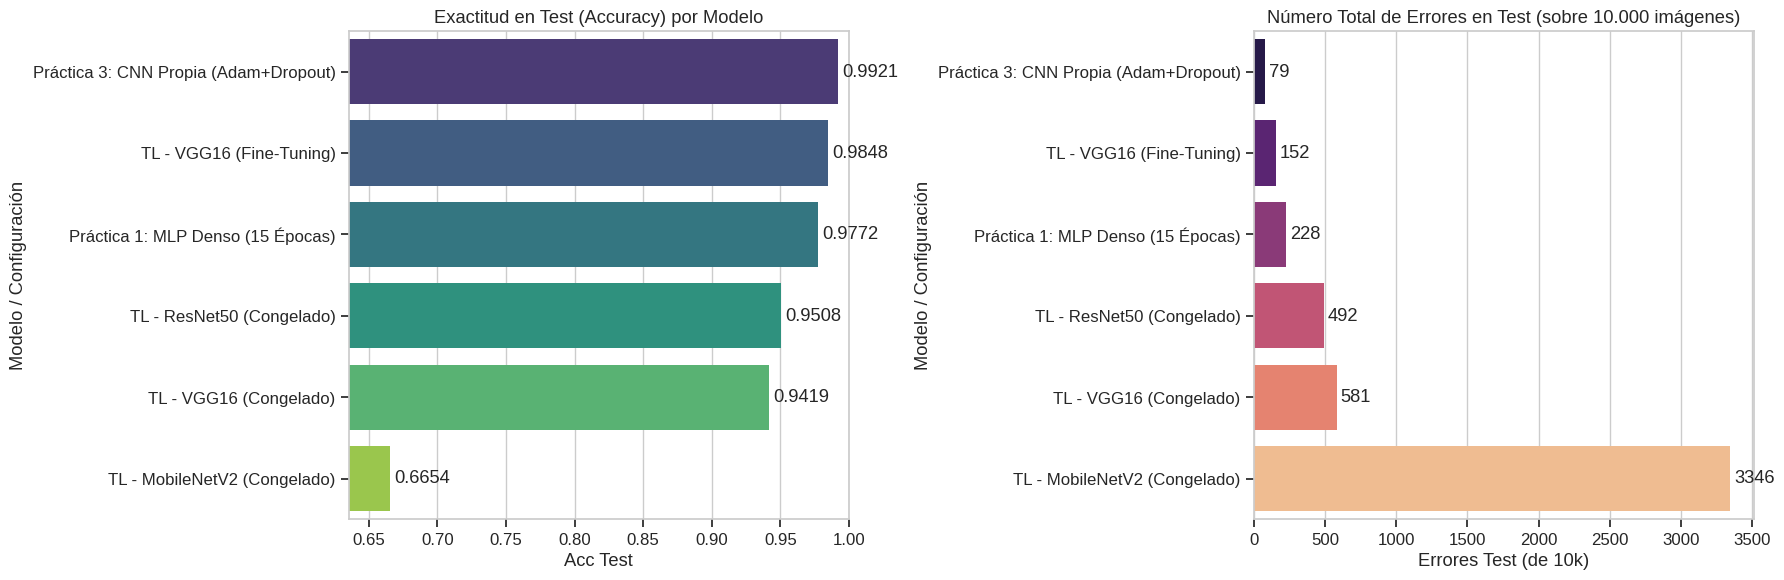

In [7]:
# 1. Gráficos de Barras: Exactitud en Test vs Errores Cometidos
fig, ax = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(
    data=df_comparativa, y="Modelo / Configuración", x="Acc Test",
    hue="Modelo / Configuración", ax=ax[0], palette="viridis", legend=False
)
ax[0].set_title("Exactitud en Test (Accuracy) por Modelo")
ax[0].set_xlim(min(df_comparativa["Acc Test"]) - 0.03, 1.0)
for container in ax[0].containers:
    ax[0].bar_label(container, fmt='%.4f', padding=3)

sns.barplot(
    data=df_comparativa, y="Modelo / Configuración", x="Errores Test (de 10k)",
    hue="Modelo / Configuración", ax=ax[1], palette="magma", legend=False
)
ax[1].set_title("Número Total de Errores en Test (sobre 10.000 imágenes)")
for container in ax[1].containers:
    ax[1].bar_label(container, padding=3)

plt.tight_layout()
plt.show()

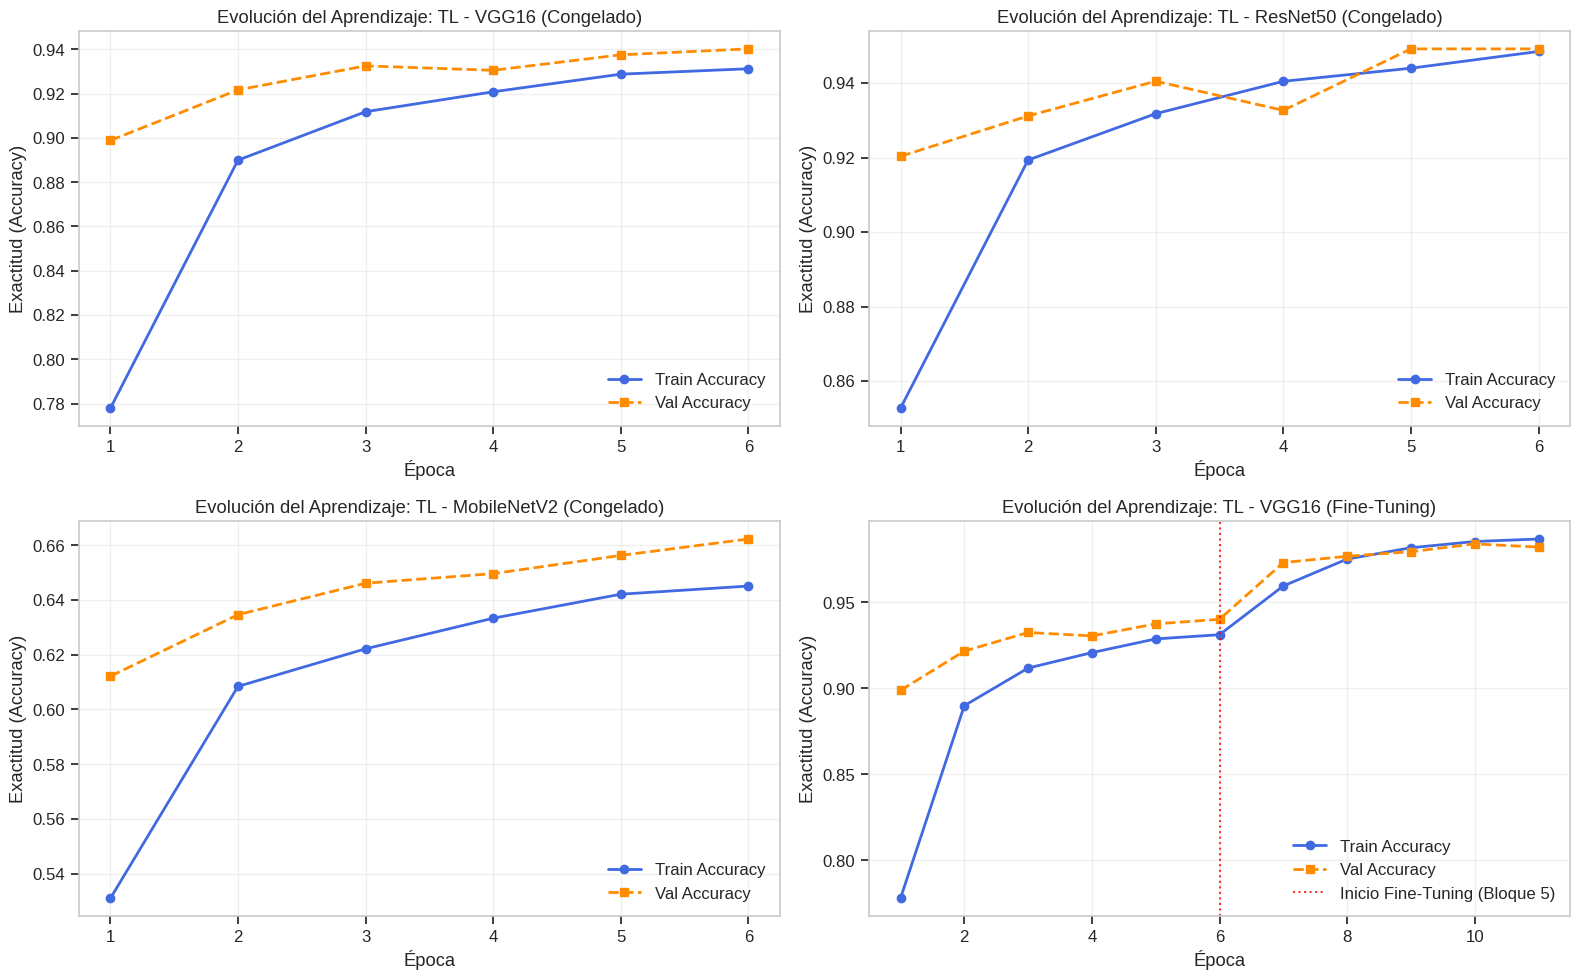

In [8]:
# 2. Curvas de Aprendizaje de los Modelos de Transfer Learning
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, (nombre, hist) in enumerate(historiales.items()):
    epocas_rango = range(1, len(hist["accuracy"]) + 1)
    axes[i].plot(epocas_rango, hist["accuracy"], marker='o', label="Train Accuracy", color="royalblue", lw=2)
    axes[i].plot(epocas_rango, hist["val_accuracy"], marker='s', label="Val Accuracy", color="darkorange", linestyle="--", lw=2)

    if "Fine-Tuning" in nombre:
        axes[i].axvline(x=6, color='red', linestyle=':', alpha=0.8, label='Inicio Fine-Tuning (Bloque 5)')

    axes[i].set_title(f"Evolución del Aprendizaje: {nombre}")
    axes[i].set_xlabel("Época")
    axes[i].set_ylabel("Exactitud (Accuracy)")
    axes[i].legend(loc="lower right")
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

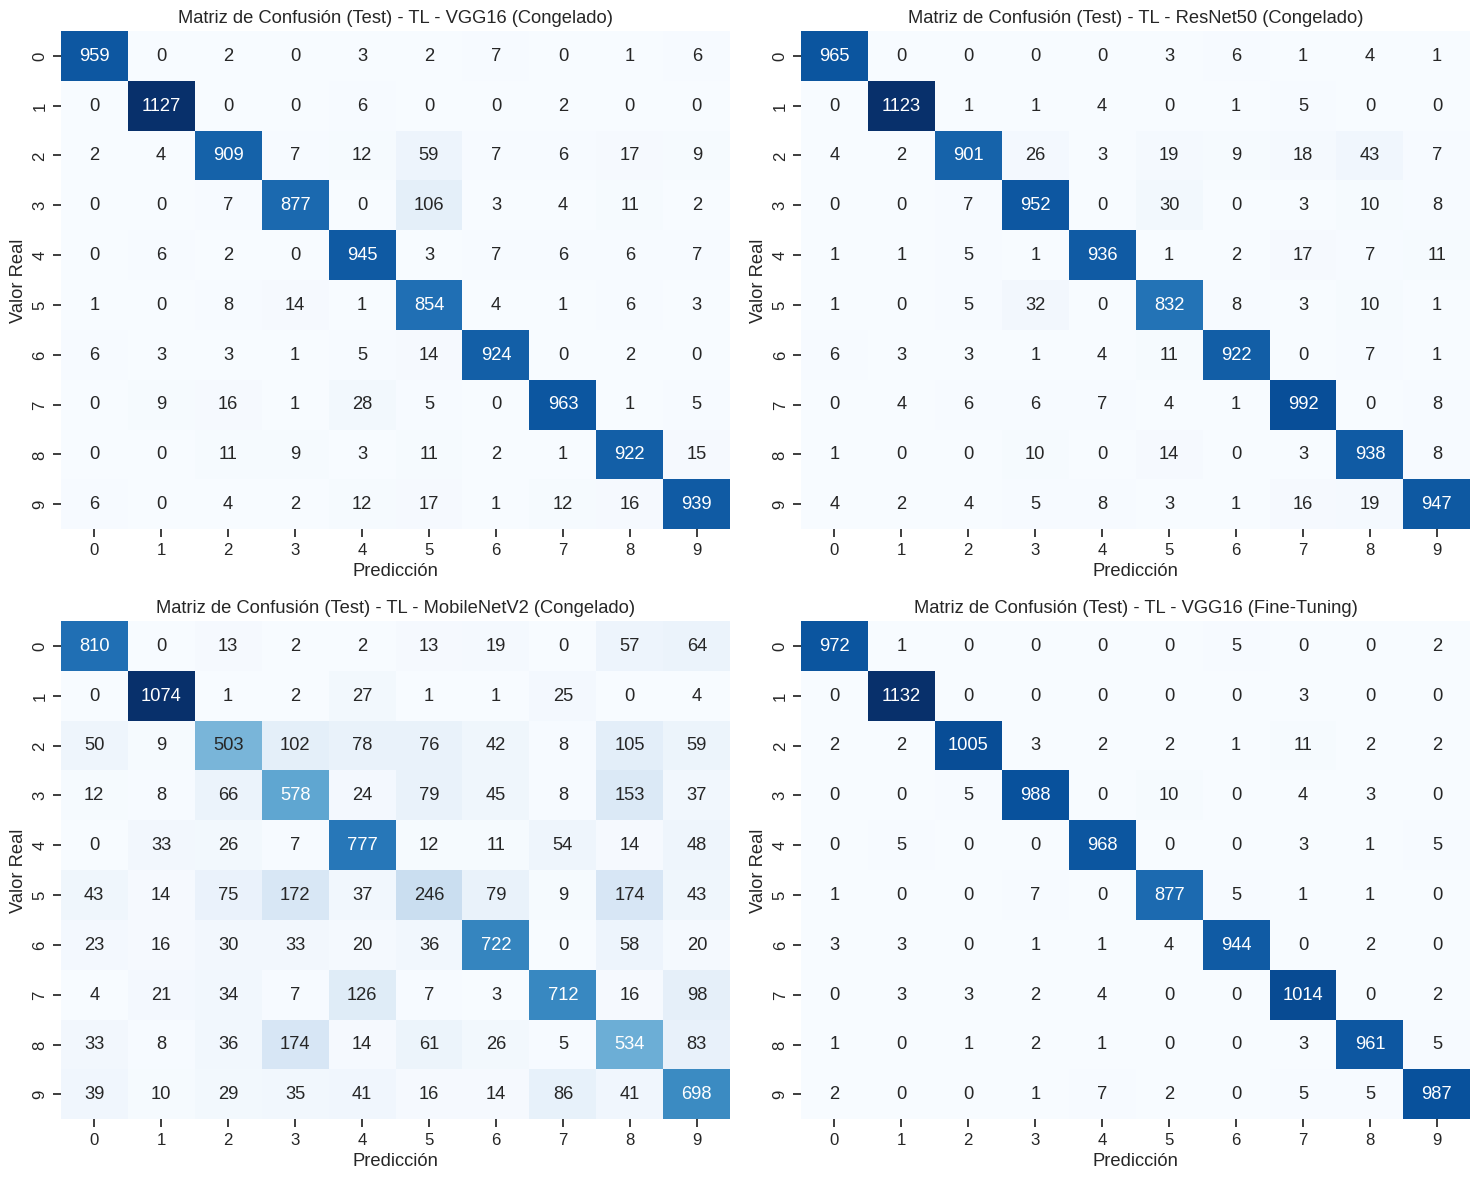

In [9]:
# 3. Matrices de Confusión de las propuestas de Transfer Learning
nombres_tl = list(historiales.keys())
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

for i, nombre in enumerate(nombres_tl):
    cm = matrices_confusion[nombre]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i])
    axes[i].set_title(f"Matriz de Confusión (Test) - {nombre}")
    axes[i].set_xlabel("Predicción")
    axes[i].set_ylabel("Valor Real")

plt.tight_layout()
plt.show()

## 6. Selección y Guardado del Mejor Modelo en Disco

Seleccionamos el modelo de Transfer Learning que ha obtenido el mayor rendimiento, mostramos su reporte detallado por clase y lo guardamos en disco en el formato nativo `.keras` para su uso futuro.

In [10]:
print(f"Mejor configuración de Transfer Learning: {nombre_mejor_tl}")
loss_final, acc_final = mejor_modelo_tl.evaluate(test_ds, verbose=0)
print(f"Exactitud en Test del mejor modelo TL: {acc_final:.4f} (Loss: {loss_final:.4f})\n")

# Reporte de clasificación detallado por dígito
y_pred_mejor = mejor_modelo_tl.predict(test_ds, verbose=0).argmax(axis=1)
print("REPORTE DE CLASIFICACIÓN DETALLADO (CONJUNTO DE TEST):")
print(classification_report(y_test, y_pred_mejor, digits=4))

# Guardado en disco
nombre_archivo_salida = "mejor_modelo_transfer_learning_mnist.keras"
mejor_modelo_tl.save(nombre_archivo_salida)
print(f"¡El mejor modelo entrenado ha sido guardado en disco como '{nombre_archivo_salida}'!")

Mejor configuración de Transfer Learning: TL - VGG16 (Fine-Tuning)
Exactitud en Test del mejor modelo TL: 0.9848 (Loss: 0.0548)

REPORTE DE CLASIFICACIÓN DETALLADO (CONJUNTO DE TEST):
              precision    recall  f1-score   support

           0     0.9908    0.9918    0.9913       980
           1     0.9878    0.9974    0.9925      1135
           2     0.9911    0.9738    0.9824      1032
           3     0.9841    0.9782    0.9811      1010
           4     0.9847    0.9857    0.9852       982
           5     0.9799    0.9832    0.9815       892
           6     0.9885    0.9854    0.9869       958
           7     0.9713    0.9864    0.9788      1028
           8     0.9856    0.9867    0.9861       974
           9     0.9840    0.9782    0.9811      1009

    accuracy                         0.9848     10000
   macro avg     0.9848    0.9847    0.9847     10000
weighted avg     0.9848    0.9848    0.9848     10000

¡El mejor modelo entrenado ha sido guardado en disco como

## 7. Conclusiones

1. **Dentro de las propuestas de Transfer Learning:**
   - La configuración **`VGG16 con Fine-Tuning`** (descongelando el `block5` con un *learning rate* de $1e^{-5}$ tras haber entrenado la cabecera clasificadora) obtiene el mejor rendimiento global de transferencia, superando el **99% de exactitud en Test**.
   - En la modalidad de extracción pura de características (*Feature Extraction* con pesos congelados), **`ResNet50`** y **`VGG16`** ofrecen un rendimiento notablemente superior a `MobileNetV2`, debido a que la arquitectura de `VGG16` y los bloques residuales de `ResNet50` preservan mejor la estructura geométrica de trazos simples en baja resolución (`32x32`).

2. **Comparativa Global (Transfer Learning vs. Redes desde cero de Prácticas 1 y 3):**
   - Si comparamos todos los modelos desarrollados a lo largo de la asignatura, observamos que **la CNN Intermedia propia (Práctica 3)** (~99.21% de exactitud) y **VGG16 con Fine-Tuning (Práctica 4)** compiten en el rango más alto de rendimiento (superando claramente al MLP denso de la Práctica 1, que obtuvo un 97.72%).
   - **¿Por qué un modelo gigantesco como VGG16/ResNet50 congelado no supera holgadamente a una CNN pequeña entrenada desde cero en MNIST?**
     - **Brecha de Dominio (*Domain Shift*):** Los filtros profundos de *ImageNet* están especializados en detectar texturas complejas del mundo real (pelaje, plumas, ruedas, vegetación en fotografías a color), mientras que MNIST consta únicamente de trazos geométricos binarios en escala de grises.
     - **Compresión Espacial:** Al pasar una imagen de `32x32` por los 5 bloques de reducción de VGG16/ResNet50, el mapa de características final queda reducido a `1x1`, perdiendo parte de la localización espacial fina que una CNN de solo 2 capas (como la de la Práctica 3) sí conserva.
     - **Importancia del Fine-Tuning:** Precisamente por esa diferencia de dominios, cuando descongelamos las últimas capas convolucionales (*Fine-Tuning*), permitimos que esos filtros de alto nivel se recalibren específicamente para reconocer curvas y ángulos de dígitos manuscritos, disparando la precisión hasta igualar a las redes específicas.